# Experimento CNN — CIFAR-10 (semilla 57)

**Universidad Andina del Cusco — Inteligencia Artificial — Evaluación de la Segunda Unidad**
**Estudiante:** Jerson Americo Peña Salgueron · **Código:** 021101457b · **Semilla:** 57

Este notebook contiene las pruebas, el análisis exploratorio (EDA) y la visualización de muestras.
Reutiliza las funciones de `src/dataset.py` y `src/model.py` para que el código sea uno solo.
El entrenamiento completo se ejecuta con `python src/train.py` (no se duplica aquí).

> Ejecute las celdas en orden con el kernel del entorno virtual `.venv`.

## 1. Importaciones y configuración de la semilla individual

In [1]:
import sys
from pathlib import Path

# Permite importar los módulos de src/ desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import random
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt

import dataset as ds
from model import CNN, count_parameters, validate_forward_pass

SEED = 57  # código 021101457b -> dos últimos dígitos
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
ds.set_seed(SEED)   # además fija cuDNN en modo determinista

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("CUDA        :", torch.cuda.is_available())
print("Semilla     :", SEED)

PyTorch     : 2.15.0+cpu
Torchvision : 0.29.2+cpu
CUDA        : False
Semilla     : 57


## 2. Carga de CIFAR-10 (`torchvision.datasets`)
La primera ejecución descarga ~170 MB en la carpeta `data/` (excluida de Git).

In [2]:
train_raw, test_raw = ds.load_raw_datasets()

print("Entrenamiento oficial:", train_raw.data.shape, "(N, H, W, C)", train_raw.data.dtype)
print("Prueba oficial       :", test_raw.data.shape)
print("Clases               :", train_raw.classes)

Entrenamiento oficial: (50000, 32, 32, 3) (N, H, W, C) uint8
Prueba oficial       : (10000, 32, 32, 3)
Clases               : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Análisis exploratorio básico (EDA)
### 3.1 Distribución de clases

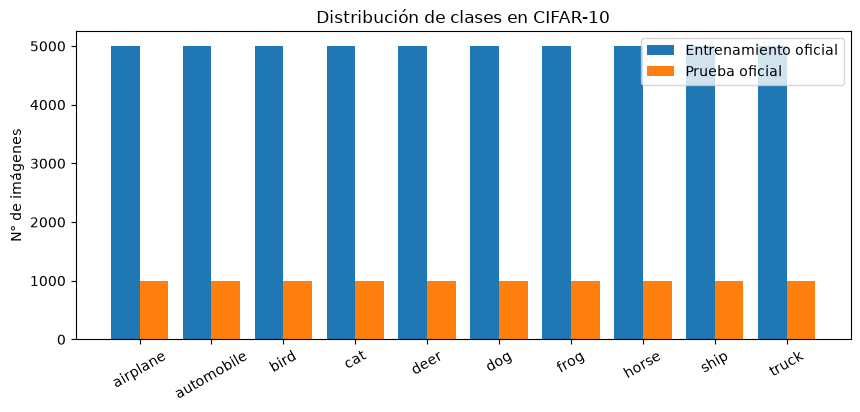

airplane    train= 5000  test= 1000
automobile  train= 5000  test= 1000
bird        train= 5000  test= 1000
cat         train= 5000  test= 1000
deer        train= 5000  test= 1000
dog         train= 5000  test= 1000
frog        train= 5000  test= 1000
horse       train= 5000  test= 1000
ship        train= 5000  test= 1000
truck       train= 5000  test= 1000


In [3]:
dist_train = ds.class_distribution(train_raw.targets)
dist_test = ds.class_distribution(test_raw.targets)

x = np.arange(len(ds.CLASSES))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, list(dist_train.values()), width=0.4, label="Entrenamiento oficial")
ax.bar(x + 0.2, list(dist_test.values()), width=0.4, label="Prueba oficial")
ax.set_xticks(x, ds.CLASSES, rotation=30)
ax.set_ylabel("N° de imágenes")
ax.set_title("Distribución de clases en CIFAR-10")
ax.legend()
plt.show()

for c in ds.CLASSES:
    print(f"{c:<11} train={dist_train[c]:>5}  test={dist_test[c]:>5}")

### 3.2 Estadísticas de píxeles por canal
Se calculan sobre el conjunto de entrenamiento para justificar los valores de `Normalize`.

In [4]:
pixels = train_raw.data.astype(np.float32) / 255.0      # (50000, 32, 32, 3) en [0, 1]
mean = pixels.mean(axis=(0, 1, 2))
std = pixels.std(axis=(0, 1, 2))
print("Media por canal (R, G, B):", np.round(mean, 4))
print("Desv. por canal (R, G, B):", np.round(std, 4))
print("Valores usados en Normalize:", ds.CIFAR10_MEAN, ds.CIFAR10_STD)

Media por canal (R, G, B): [0.4914 0.4822 0.4465]
Desv. por canal (R, G, B): [0.247  0.2435 0.2616]
Valores usados en Normalize: (0.4914, 0.4822, 0.4465) (0.247, 0.2435, 0.2616)


## 4. Visualización de muestras con su etiqueta real (16 imágenes)

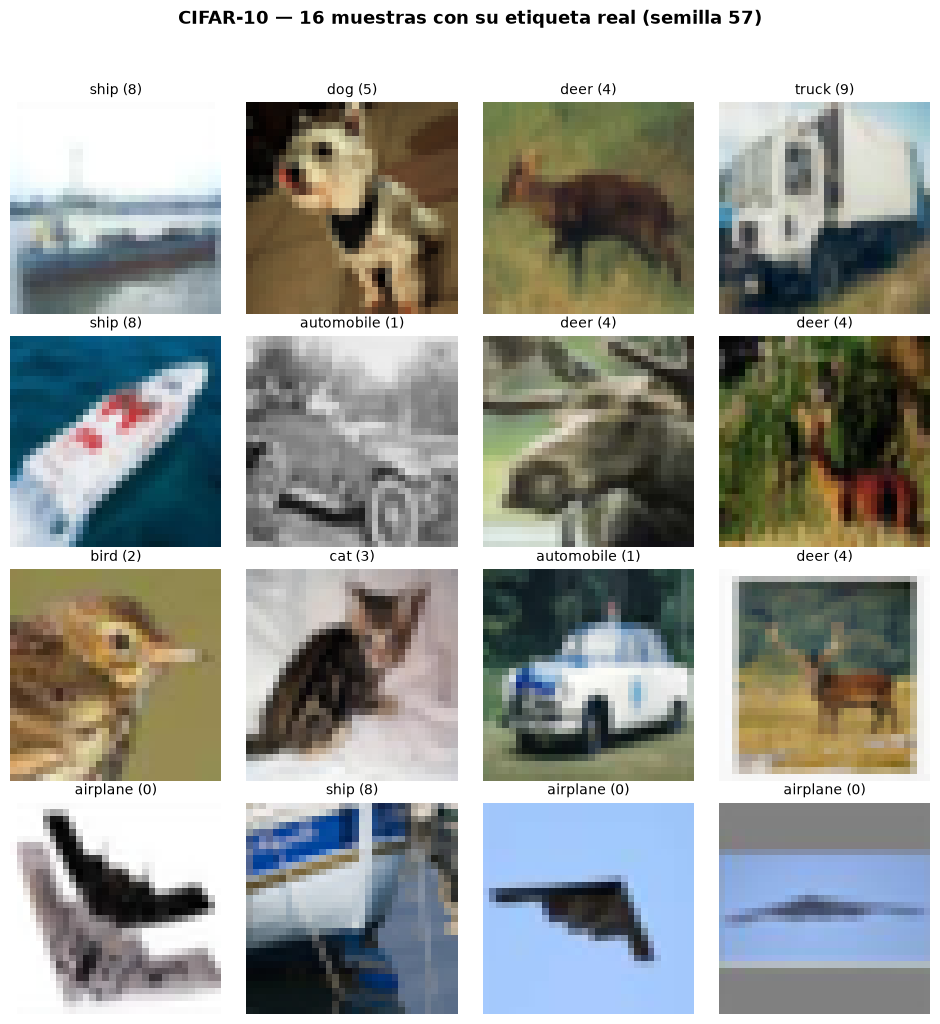

In [5]:
ds.show_samples(train_raw, n_images=16, seed=SEED)

## 5. Pipeline de transformaciones

| Conjunto | Transformaciones | ¿Aleatorio? |
|---|---|---|
| Entrenamiento | `RandomCrop(32, padding=4)` → `RandomHorizontalFlip(0.5)` → `ToTensor()` → `Normalize(media, desv)` | Sí (Data Augmentation) |
| Validación / Prueba | `ToTensor()` → `Normalize(media, desv)` | No |

El aumento de datos solo se aplica al entrenamiento: así la validación y la prueba miden el rendimiento siempre sobre las mismas imágenes.

In [6]:
train_tf, eval_tf = ds.get_transforms()
print("Entrenamiento:", train_tf)
print("Evaluación   :", eval_tf)

img, label = train_raw[0]                 # imagen PIL original
t = eval_tf(img)
print("\nToTensor + Normalize ->", tuple(t.shape), t.dtype)
print("Media por canal tras normalizar:", t.mean(dim=(1, 2)).numpy().round(3))

Entrenamiento: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)
Evaluación   : Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

ToTensor + Normalize -> (3, 32, 32) torch.float32
Media por canal tras normalizar: [ 0.252 -0.288 -0.747]


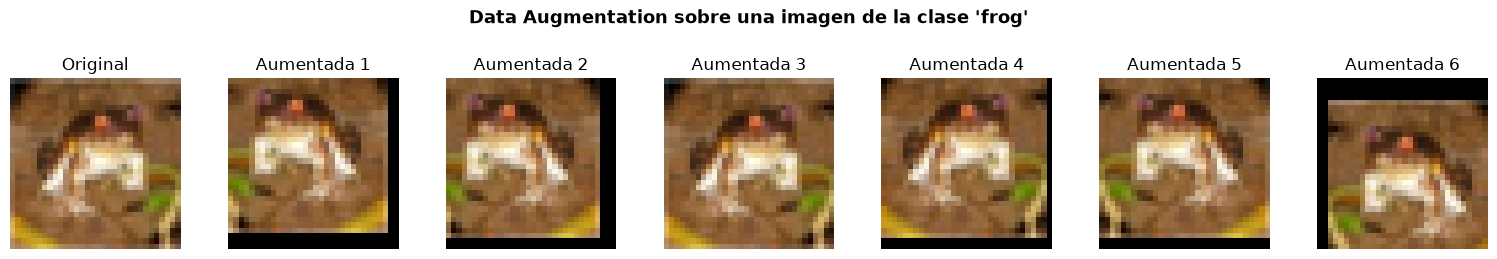

In [7]:
# Misma imagen pasada varias veces por el pipeline de entrenamiento
ds.show_augmentations(train_raw, index=0, n_versions=6)

## 6. Partición estratificada (80 % entrenamiento / 20 % validación)

In [8]:
train_loader, val_loader, test_loader, info = ds.get_dataloaders(batch_size=64, val_size=0.2)

dist_tr = ds.class_distribution(info["targets"], info["train_idx"])
dist_va = ds.class_distribution(info["targets"], info["val_idx"])
print(f"\n{'clase':<11}{'train':>7}{'val':>7}{'% val':>8}")
for c in ds.CLASSES:
    print(f"{c:<11}{dist_tr[c]:>7}{dist_va[c]:>7}{100*dist_va[c]/(dist_tr[c]+dist_va[c]):>7.1f}%")

overlap = np.intersect1d(info["train_idx"], info["val_idx"])
assert overlap.size == 0
print("\nSin solapamiento entre entrenamiento y validación:", overlap.size == 0)

PARTICIÓN ESTRATIFICADA (semilla = 57, validación = 20%)
Entrenamiento oficial completo :  50000 imágenes
  -> Subconjunto entrenamiento :  40000 imágenes
  -> Subconjunto validación    :  10000 imágenes
Prueba (independiente)         :  10000 imágenes
Índices solapados train/val    : 0
Lotes por época -> train: 625, val: 157, test: 157

clase        train    val   % val
airplane      4000   1000   20.0%
automobile    4000   1000   20.0%
bird          4000   1000   20.0%
cat           4000   1000   20.0%
deer          4000   1000   20.0%
dog           4000   1000   20.0%
frog          4000   1000   20.0%
horse         4000   1000   20.0%
ship          4000   1000   20.0%
truck         4000   1000   20.0%

Sin solapamiento entre entrenamiento y validación: True


## 7. Tensores 4D: formato NCHW

PyTorch representa un lote de imágenes como un tensor de 4 dimensiones **(Batch_Size, Channels, Height, Width)**:

- **N / Batch_Size**: cuántas imágenes hay en el lote (64).
- **C / Channels**: canales de color (3 = R, G, B).
- **H, W**: alto y ancho en píxeles (32 × 32).

`ToTensor()` convierte la imagen de formato HWC (alto, ancho, canal) a CHW, y el DataLoader apila 64 de ellas en la dimensión N.

In [9]:
images, labels = next(iter(train_loader))
print("images:", tuple(images.shape), "-> (Batch, Channels, Height, Width)")
print("labels:", tuple(labels.shape))
print("Una imagen:", tuple(images[0].shape), "| un canal:", tuple(images[0, 0].shape))
print("Etiquetas del lote (primeras 10):", [ds.CLASSES[i] for i in labels[:10]])

images: (64, 3, 32, 32) -> (Batch, Channels, Height, Width)
labels: (64,)
Una imagen: (3, 32, 32) | un canal: (32, 32)
Etiquetas del lote (primeras 10): ['truck', 'airplane', 'frog', 'truck', 'deer', 'frog', 'deer', 'airplane', 'truck', 'cat']


## 8. Prueba del modelo CNN y validación del forward pass

In [10]:
torch.manual_seed(SEED)
model = CNN()
print(model)
print(f"\nTamaño aplanado calculado dinámicamente: {model.flatten_size}")
print(f"Parámetros entrenables: {count_parameters(model):,}")

CNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

Tamaño aplanado calculado dinámicamente: 4096
Parámetros entrenables: 545,098


In [11]:
# 8.1 Lote SIMULADO (aserciones incluidas)
_ = validate_forward_pass(model, batch_size=8)

VALIDACIÓN DEL FORWARD PASS (lote simulado)
Etapa                                 Shape de salida             
------------------------------------------------------------------
Entrada                               [8, 3, 32, 32]              
block1.Conv2d                         [8, 32, 32, 32]             
block1.ReLU                           [8, 32, 32, 32]             
block1.MaxPool2d                      [8, 32, 16, 16]             
block2.Conv2d                         [8, 64, 16, 16]             
block2.ReLU                           [8, 64, 16, 16]             
block2.MaxPool2d                      [8, 64, 8, 8]               
Flatten                               [8, 4096]                   
classifier.Linear                     [8, 128]                    
classifier.ReLU                       [8, 128]                    
classifier.Dropout                    [8, 128]                    
classifier.Linear                     [8, 10]                     
------------------

In [12]:
# 8.2 Lote REAL del DataLoader
model.eval()
with torch.no_grad():
    logits = model(images)
probs = torch.softmax(logits, dim=1)   # Softmax solo para interpretar; la pérdida usa logits
print("Entrada real :", tuple(images.shape))
print("Logits       :", tuple(logits.shape))
print("Suma de probabilidades de la 1.ª imagen:", round(probs[0].sum().item(), 4))
assert logits.shape == (images.shape[0], 10)

Entrada real : (64, 3, 32, 32)
Logits       : (64, 10)
Suma de probabilidades de la 1.ª imagen: 1.0


## 9. Resultados del entrenamiento
Ejecute primero `python src/train.py`. Esta celda solo muestra las gráficas generadas en `outputs/`.

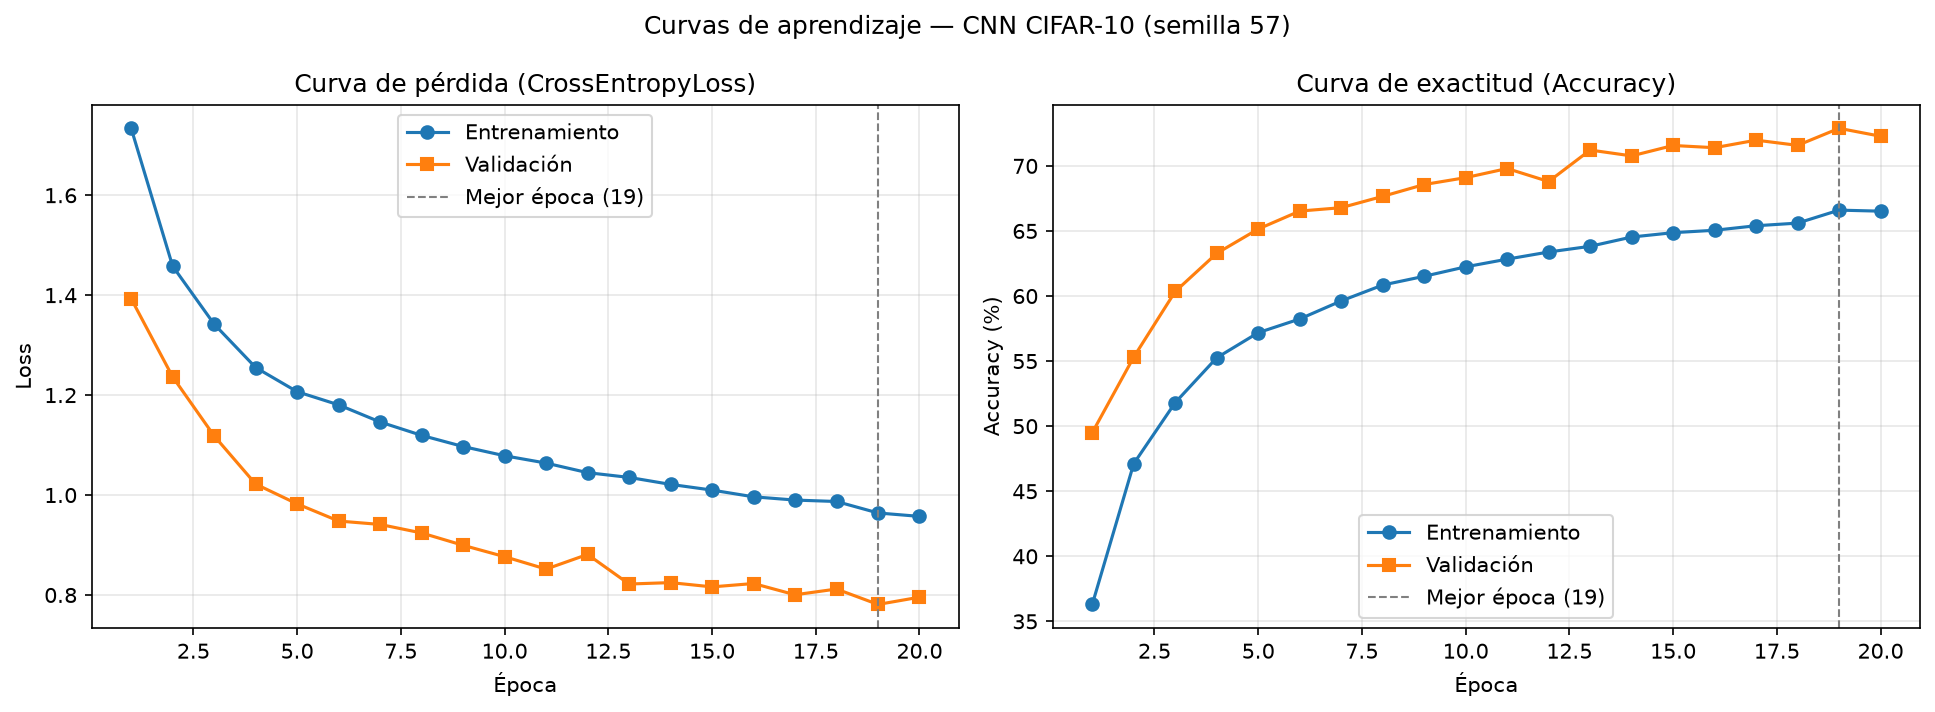

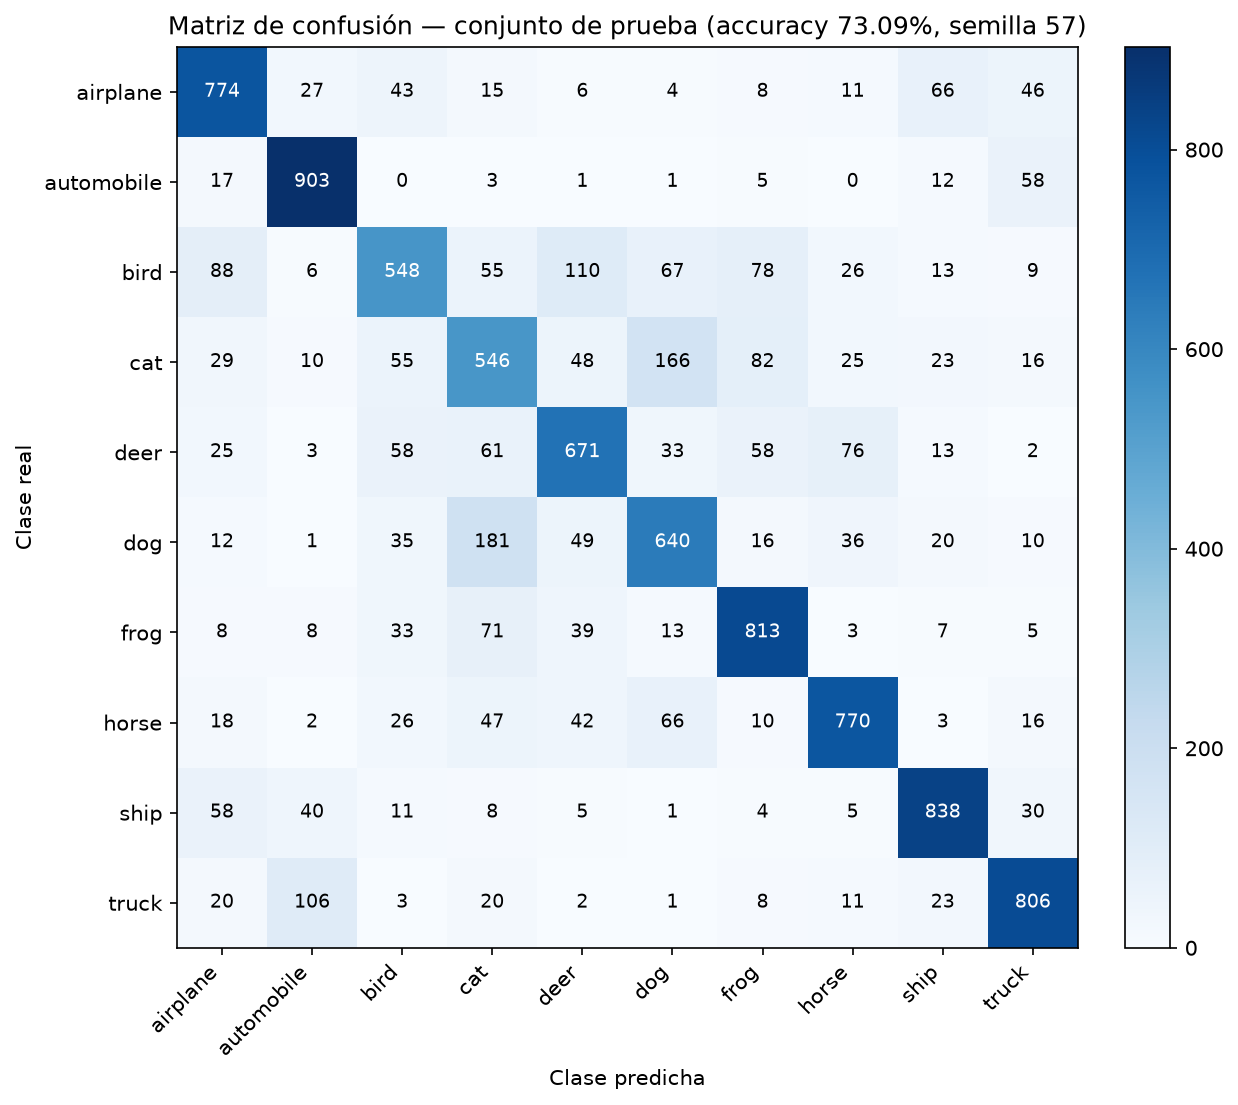

# Resumen de resultados (semilla 57)

- Dispositivo: `cpu`
- Épocas: 20 | batch: 64 | lr: 0.001 | weight_decay: 0.0 | dropout: 0.5
- Parámetros entrenables: 545,098
- Tiempo total de entrenamiento: 7.9 min

## Métricas por época

| Época | Train Loss | Train Acc (%) | Val Loss | Val Acc (%) |
|---:|---:|---:|---:|---:|
| 1 | 1.7339 | 36.30 | 1.3930 | 49.50 |
| 2 | 1.4581 | 47.12 | 1.2365 | 55.31 |
| 3 | 1.3420 | 51.81 | 1.1184 | 60.35 |
| 4 | 1.2553 | 55.26 | 1.0220 | 63.28 |
| 5 | 1.2069 | 57.19 | 0.9824 | 65.15 |
| 6 | 1.1805 | 58.24 | 0.9480 | 66.53 |
| 7 | 1.1462 | 59.62 | 0.9412 | 66.79 |
| 8 | 1.1195 | 60.84 | 0.9242 | 67.66 |
| 9 | 1.0971 | 61.52 | 0.8995 | 68.57 |
| 10 | 1.0787 | 62.24 | 0.8767 | 69.10 |
| 11 | 1.0640 | 62.84 | 0.8518 | 69.80 |
| 12 | 1.0448 | 63.38 | 0.8812 | 68.80 |
| 13 | 1.0353 | 63.82 | 0.8220 | 71.22 |
| 14 | 1.0214 | 64.53 | 0.8248 | 70.77 |
| 15 | 1.0100 | 64.87 | 0.8163 | 71.57 |
| 16 | 0.9965 | 65.06 | 0.8230 | 71.40 |
| 17 | 0.9900 | 65.40 | 0.8005 | 71.98 |
| 18 | 0.9871 | 65.61 | 0.8119 | 71.58 |
| 19 **(mejor)** | 0.9642 | 66.60 | 0.7811 | 72.89 |
| 20 | 0.9573 | 66.52 | 0.7956 | 72.28 |

## Conjunto de prueba (10 000 imágenes, modelo de la mejor época)

- Test Loss: **0.7799**
- Test Accuracy: **73.09 %**

| Clase | Precision | Recall | F1-score |
|---|---:|---:|---:|
| airplane | 0.738 | 0.774 | 0.755 |
| automobile | 0.816 | 0.903 | 0.858 |
| bird | 0.675 | 0.548 | 0.605 |
| cat | 0.542 | 0.546 | 0.544 |
| deer | 0.690 | 0.671 | 0.680 |
| dog | 0.645 | 0.640 | 0.643 |
| frog | 0.751 | 0.813 | 0.781 |
| horse | 0.800 | 0.770 | 0.785 |
| ship | 0.823 | 0.838 | 0.831 |
| truck | 0.808 | 0.806 | 0.807 |

## Diagnóstico automático (orientativo)

- Brecha de accuracy train-val (última época): -5.76 puntos
- Brecha de accuracy train-val (mejor época): -6.29 puntos
- Val loss mínima: 0.7811 (época 19)
- Aumento de val loss desde su mínimo: 0.0145
- Síntomas de UNDERFITTING: el accuracy de entrenamiento sigue por debajo de 70 %; el modelo aún no se ajusta bien ni a los datos que ve.
- Validación > entrenamiento: es esperable con Data Augmentation y Dropout, porque el accuracy de entrenamiento se mide sobre imágenes alteradas y con neuronas apagadas, mientras la validación usa imágenes limpias y modo eval.


In [13]:
from IPython.display import Image, Markdown, display

for name in ("loss_accuracy.png", "confusion_matrix.png"):
    path = ROOT / "outputs" / name
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"Aún no existe {path.name}: ejecute python src/train.py")

summary = ROOT / "outputs" / "results_summary.md"
if summary.exists():
    display(Markdown(summary.read_text(encoding="utf-8")))